# Tiempo en redes sociales vs Enfermedades mentales  

**Integrantes**

Juan Diego Cárdenas López - 2234515

Juan David Ardila Flórez - 2234666

# **Introducción**

Crear un modelo de IA que analice la relacion entre el tiempo medio que una persona pasa en redes sociales y las enfermedades mentales que pueda llegar a tener, además, tendra en cuenta factores como la edad, tipo de trabajo, estado civil, plataforma principal, horas de uso del celular, etc.

#Importarción de librerias

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Preprocesamiento
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder

# Estimadores
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
import tensorflow as tf
from tensorflow import keras

from google.colab import drive

#Carga del datset

In [5]:
drive.mount('/content/drive')
df = pd.read_csv("/content/drive/MyDrive/IA_2026-2/social_media_addiction_mental_wellbeing.csv")

Mounted at /content/drive


#Nomalización y Limpieza

**Cambio respecto a la entrega anterior:** ya no se usa `dropna()`. Los valores faltantes están dispersos (~50 por columna en ~21 columnas), así que borrar filas dejaba solo 672 de 1500 registros. Ahora se **imputan** (mediana en numéricas, moda en categóricas) dentro de un `Pipeline` ajustado solo con train, para no filtrar información del test.

In [6]:
df = df.drop(columns=['First_Check_Morning', 'Tried_To_Cut_Back', 'Failed_To_Cut_Back', 'User_ID'])
print(df.shape)
print(df.isna().sum().sum(), "valores faltantes (se imputan más adelante)")

(1500, 26)
1061 valores faltantes (se imputan más adelante)


In [7]:
df.describe()

,Age,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Notifications_Per_Day,FOMO_Score,Social_Comparison_Score,Validation_Seeking_Score,Scroll_Without_Purpose,Anxiety_Score,Depression_Score,Loneliness_Score,Self_Esteem_Score,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score
count,1500.000000,1444.000000,1500.000000,1500.000000,1500.000000,1445.000000,1449.000000,1442.000000,1500.000000,1452.000000,1445.000000,1445.000000,1431.000000,1432.000000,1438.000000,1449.000000,1430.000000,1449.000000,1440.000000,1500.000000
mean,29.372000,4.521399,3.236000,3.936000,60.244667,5.445882,5.495514,5.013107,5.449867,5.110537,4.562630,4.484429,5.519846,5.508659,6.557580,5.026570,5.482797,3.016494,3.025903,6.429733
std,8.550459,2.108319,1.682714,1.948273,33.150688,2.183914,2.041919,2.112417,2.083848,2.157587,2.199201,1.997623,1.993134,1.997842,1.380144,2.114049,2.045514,1.715963,1.691351,1.299288
min,15.000000,0.500000,1.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.500000
25%,22.000000,3.100000,2.000000,3.000000,36.000000,4.000000,4.100000,3.600000,4.000000,3.700000,3.100000,3.100000,4.200000,4.100000,5.600000,3.600000,4.100000,1.800000,1.800000,5.500000
50%,29.000000,4.400000,3.000000,4.000000,59.000000,5.500000,5.500000,5.000000,5.500000,5.100000,4.500000,4.500000,5.600000,5.500000,6.600000,5.000000,5.400000,3.000000,3.000000,6.400000
75%,37.000000,5.900000,4.000000,5.000000,81.250000,7.000000,6.900000,6.500000,6.900000,6.600000,6.000000,5.900000,6.900000,6.900000,7.500000,6.400000,7.000000,4.200000,4.200000,7.300000
max,44.000000,12.000000,8.000000,12.000000,165.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,8.900000,10.300000,10.000000


In [8]:
df.head(10)

,Age,Gender,Occupation,Relationship_Status,Primary_Platform,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Late_Night_Usage,Notifications_Per_Day,...,Loneliness_Score,Self_Esteem_Score,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score,Addiction_Level
0,30,Male,Working Professional,In a Relationship,YouTube,2.9,4,3,No,62,...,1.7,6.5,8.5,5.3,3.7,3.8,5.8,3.1,7.3,Low
1,19,Male,Student,Married,Instagram,4.8,1,0,NaN,111,...,7.0,7.5,7.8,5.5,4.0,1.8,0.9,3.3,4.1,Severe
2,40,Male,Student,In a Relationship,YouTube,NaN,4,5,No,122,...,5.6,5.3,6.3,NaN,5.8,2.8,0.0,1.5,5.6,High
3,37,Female,Student,Married,Facebook,7.7,2,3,Yes,48,...,5.6,1.4,3.9,6.1,5.5,3.6,1.0,3.9,4.3,Severe
4,18,Non-binary,Student,In a Relationship,TikTok,4.6,3,0,No,58,...,4.0,NaN,5.7,5.0,3.8,3.2,0.6,1.0,6.6,Moderate
5,34,Male,Working Professional,Married,YouTube,1.2,1,3,No,37,...,5.0,7.9,NaN,5.6,2.8,5.6,4.1,1.5,7.7,Low
6,38,Female,Student,In a Relationship,Facebook,5.0,4,4,Yes,24,...,7.2,0.5,4.8,8.2,6.8,5.4,3.2,3.7,5.5,High
7,22,Female,Unemployed,Single,Twitter/X,3.4,5,2,No,64,...,3.1,2.9,3.8,10.0,6.8,6.7,NaN,6.6,6.2,Moderate
8,43,Female,Student,Single,YouTube,9.2,4,2,No,115,...,3.8,5.1,3.2,5.7,3.2,5.4,4.8,0.6,3.4,Severe
9,40,Male,Student,Single,Instagram,6.9,2,5,Yes,62,...,3.9,8.1,7.4,5.8,6.4,7.2,4.6,0.0,7.7,Low


In [9]:
df.columns

Index(['Age', 'Gender', 'Occupation', 'Relationship_Status',
       'Primary_Platform', 'Daily_Usage_Hours', 'Platforms_Used_Count',
       'Posts_Per_Week', 'Late_Night_Usage', 'Notifications_Per_Day',
       'FOMO_Score', 'Social_Comparison_Score', 'Validation_Seeking_Score',
       'Scroll_Without_Purpose', 'Anxiety_Score', 'Depression_Score',
       'Loneliness_Score', 'Self_Esteem_Score', 'Sleep_Quality_Score',
       'Sleep_Hours', 'Productivity_Loss_Score',
       'Offline_Relationship_Quality', 'Physical_Activity_Hrs_Week',
       'Screen_Free_Time_Hrs', 'Mental_Wellbeing_Score', 'Addiction_Level'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Age                           1500 non-null   int64  
 1   Gender                        1447 non-null   object 
 2   Occupation                    1455 non-null   object 
 3   Relationship_Status           1449 non-null   object 
 4   Primary_Platform              1447 non-null   object 
 5   Daily_Usage_Hours             1444 non-null   float64
 6   Platforms_Used_Count          1500 non-null   int64  
 7   Posts_Per_Week                1500 non-null   int64  
 8   Late_Night_Usage              1450 non-null   object 
 9   Notifications_Per_Day         1500 non-null   int64  
 10  FOMO_Score                    1445 non-null   float64
 11  Social_Comparison_Score       1449 non-null   float64
 12  Validation_Seeking_Score      1442 non-null   float64
 13  Scr

In [11]:
df['Addiction_Level'].unique()

array(['Low', 'Severe', 'High', 'Moderate'], dtype=object)

In [12]:
# 1. Calcular Q1 (25%) y Q3 (75%)
Q1 = df['Sleep_Hours'].quantile(0.25)
Q3 = df['Sleep_Hours'].quantile(0.75)

# 2. Calcular el IQR
IQR = Q3 - Q1

# 3. Definir límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 4. Imprimir
print("limite inferior:", limite_inferior)
print("limite superior:", limite_superior)

limite inferior: 2.749999999999999
limite superior: 10.350000000000001


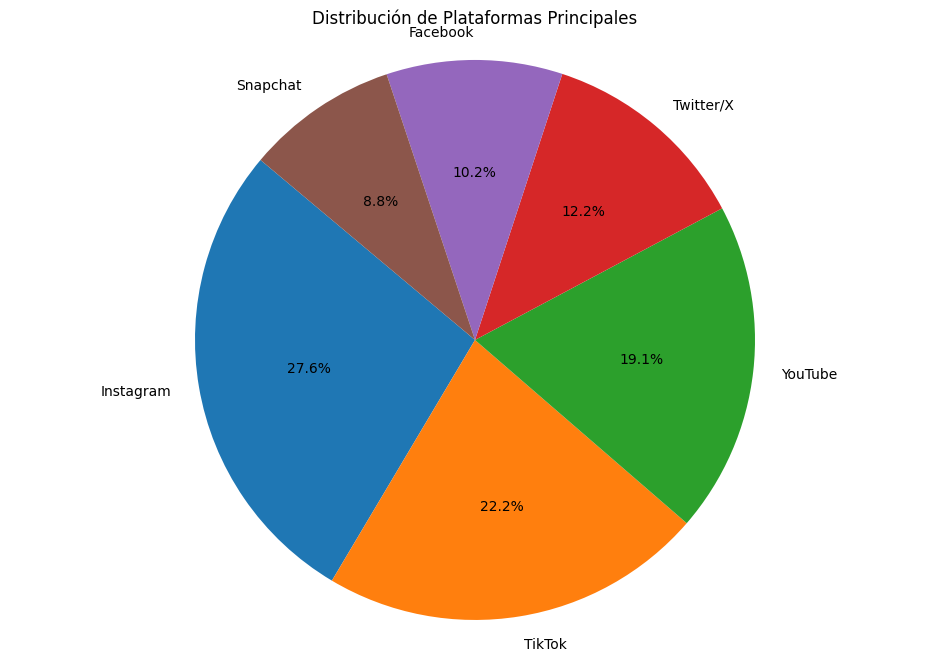

In [13]:
conteo_apps = df['Primary_Platform'].value_counts()

plt.figure(figsize=(12, 8))
plt.pie(conteo_apps, labels=conteo_apps.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribución de Plataformas Principales')
plt.axis('equal')
plt.show()

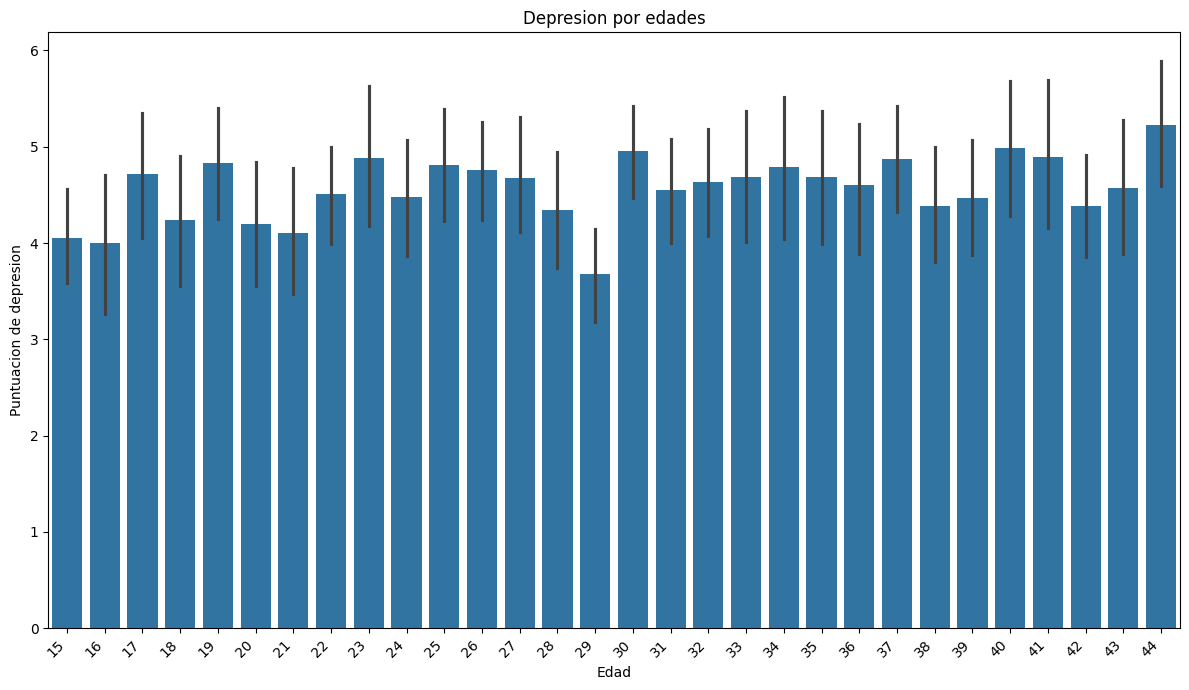

In [14]:
plt.figure(figsize=(12, 7))
sns.barplot(x='Age', y='Depression_Score', data=df)
plt.title('Depresion por edades')
plt.xlabel('Edad')
plt.ylabel('Puntuacion de depresion')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#Clasificacion

Definición del *ground truth* y de los conjuntos de entrenamiento y prueba. Se usa `stratify=y` para conservar la proporción de clases. Las variables categóricas se codifican con *one-hot* (no tienen orden, así que `factorize` inventaba un orden falso) y las numéricas se escalan. El preprocesamiento se ajusta **solo con train**.

In [15]:
y = df['Addiction_Level']
X = df.drop(columns=['Addiction_Level'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y)

cat_cols = X.select_dtypes('object').columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

def make_prep():
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols),
    ])

# Matrices procesadas (fit solo con train) para el modelo de Deep Learning
prep = make_prep()
X_train_p = prep.fit_transform(X_train)
X_test_p  = prep.transform(X_test)

# Validación cruzada estratificada: se usa para ELEGIR hiperparámetros (el test no se toca)
cv5 = StratifiedKFold(5, shuffle=True, random_state=21)

def cv_acc(est):
    """Accuracy medio en CV sobre train (preprocesamiento dentro de cada fold)."""
    return cross_val_score(make_pipeline(make_prep(), est), X_train, y_train, cv=cv5).mean()

def test_acc(est):
    """Entrena con train completo y evalúa UNA vez en test."""
    p = make_pipeline(make_prep(), est).fit(X_train, y_train)
    return accuracy_score(y_test, p.predict(X_test))

print(X_train.shape, X_test.shape)

(1200, 25) (300, 25)


###Decision Tree

In [16]:
profundidad = [1, 2, 5, 10, 15, 25, 40, 60]
acuracy = []

for i in profundidad:
    acc = cv_acc(DecisionTreeClassifier(max_depth=i, random_state=21))
    acuracy.append(acc)
    print(f'Con max_depth: {i}, el accuracy (CV) es: {acc:.4f}')

mejor_profundidad = profundidad[int(np.argmax(acuracy))]
mejor_acc = test_acc(DecisionTreeClassifier(max_depth=mejor_profundidad, random_state=21))
print(f'\n--Mejor max_depth (por CV): {mejor_profundidad} | accuracy en test: {mejor_acc:.4f}--')

Con max_depth: 1, el accuracy (CV) es: 0.4883
Con max_depth: 2, el accuracy (CV) es: 0.6608
Con max_depth: 5, el accuracy (CV) es: 0.7267
Con max_depth: 10, el accuracy (CV) es: 0.6750
Con max_depth: 15, el accuracy (CV) es: 0.6667
Con max_depth: 25, el accuracy (CV) es: 0.6692
Con max_depth: 40, el accuracy (CV) es: 0.6692
Con max_depth: 60, el accuracy (CV) es: 0.6692

--Mejor max_depth (por CV): 5 | accuracy en test: 0.7133--


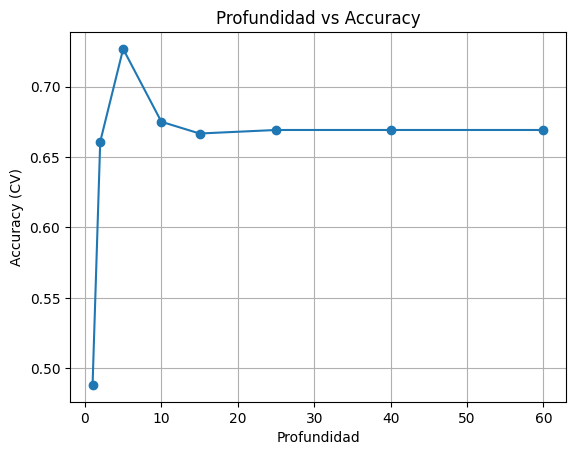

In [17]:
plt.plot(profundidad, acuracy, marker='o')
plt.xlabel('Profundidad')
plt.ylabel('Accuracy (CV)')
plt.title('Profundidad vs Accuracy')
plt.grid(True)
plt.show()

In [18]:
def show_curve(est, color="blue", titulo=""):
    """Accuracy vs número de folds (CV estratificada sobre todo el dataset, con preprocesamiento dentro del fold)."""
    means, stds = [], []
    nfolds_range = range(2, 10)
    for nfolds in nfolds_range:
        s = cross_val_score(make_pipeline(make_prep(), est), X, y,
                            cv=StratifiedKFold(nfolds, shuffle=True, random_state=21))
        means.append(np.mean(s)); stds.append(np.std(s))
    means = np.r_[means]; stds = np.r_[stds]

    plt.figure(figsize=(10, 6))
    plt.plot(nfolds_range, means, label="mean", color="black")
    plt.fill_between(nfolds_range, means-stds, means+stds, color=color, alpha=.5, label="std")
    plt.xlabel("n folds"); plt.ylabel("performance (accuracy)")
    plt.title(f"Curva por número de Folds {titulo}")
    plt.grid(True); plt.legend(); plt.show()

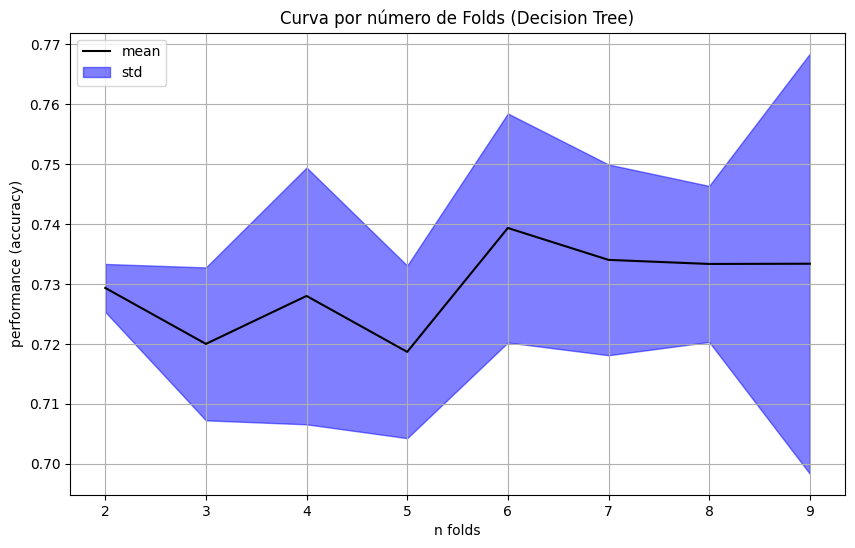

In [19]:
show_curve(DecisionTreeClassifier(max_depth=mejor_profundidad, random_state=21), 'blue', '(Decision Tree)')

###Random Forest

In [20]:
n_estimator = [10, 50, 100, 150, 200, 300, 500]
accuracy = []

for n in n_estimator:
    acc = cv_acc(RandomForestClassifier(n_estimators=n, random_state=21))
    accuracy.append(acc)
    print(f'Con n_estimators: {n}, el accuracy (CV) es: {acc:.4f}')

mejor_estimator = n_estimator[int(np.argmax(accuracy))]
mejor_rf_acc = test_acc(RandomForestClassifier(n_estimators=mejor_estimator, random_state=21))
print(f'\n--Mejor n_estimators (por CV): {mejor_estimator} | accuracy en test: {mejor_rf_acc:.4f}--')

Con n_estimators: 10, el accuracy (CV) es: 0.6308
Con n_estimators: 50, el accuracy (CV) es: 0.7342
Con n_estimators: 100, el accuracy (CV) es: 0.7475
Con n_estimators: 150, el accuracy (CV) es: 0.7500
Con n_estimators: 200, el accuracy (CV) es: 0.7433
Con n_estimators: 300, el accuracy (CV) es: 0.7492
Con n_estimators: 500, el accuracy (CV) es: 0.7492

--Mejor n_estimators (por CV): 150 | accuracy en test: 0.7333--


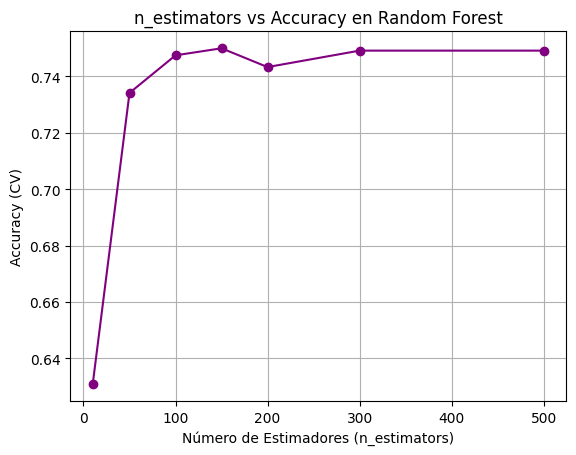

In [21]:
plt.plot(n_estimator, accuracy, marker='o', color='purple')
plt.xlabel('Número de Estimadores (n_estimators)')
plt.ylabel('Accuracy (CV)')
plt.title('n_estimators vs Accuracy en Random Forest')
plt.grid(True)
plt.show()

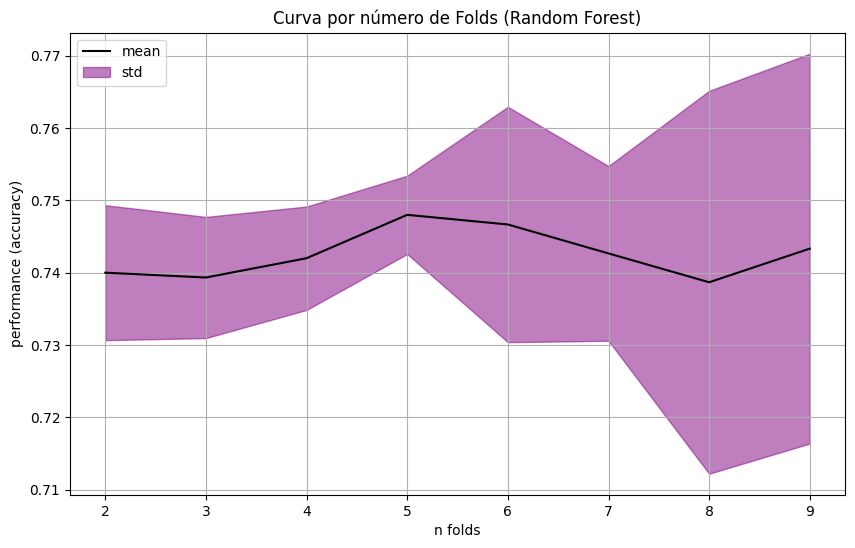

In [22]:
show_curve(RandomForestClassifier(n_estimators=mejor_estimator, random_state=21), 'purple', '(Random Forest)')

###SVM

In [23]:
kernels = ['linear', 'poly', 'rbf']
svm_accuracy = []

for k in kernels:
    acc = cv_acc(SVC(kernel=k, random_state=21))
    svm_accuracy.append(acc)
    print(f'Con kernel {k}, el accuracy (CV) es: {acc:.4f}')

mejor_kernel = kernels[int(np.argmax(svm_accuracy))]
mejor_svm_acc = test_acc(SVC(kernel=mejor_kernel, random_state=21))
print(f'\n--Mejor kernel (por CV): {mejor_kernel} | accuracy en test: {mejor_svm_acc:.4f}--')

Con kernel linear, el accuracy (CV) es: 0.7633
Con kernel poly, el accuracy (CV) es: 0.6125
Con kernel rbf, el accuracy (CV) es: 0.7008

--Mejor kernel (por CV): linear | accuracy en test: 0.7267--


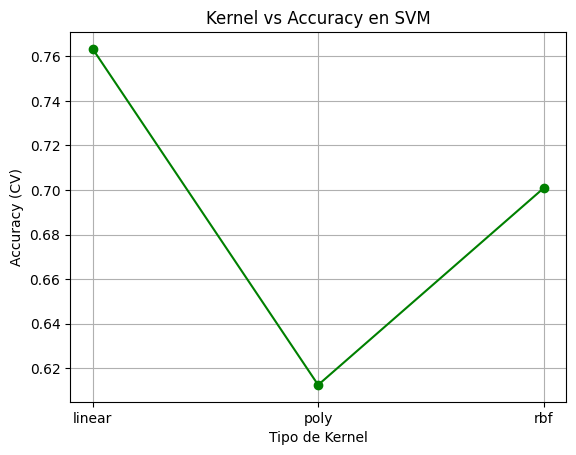

In [24]:
plt.plot(kernels, svm_accuracy, marker='o', color='green')
plt.xlabel('Tipo de Kernel')
plt.ylabel('Accuracy (CV)')
plt.title('Kernel vs Accuracy en SVM')
plt.grid(True)
plt.show()

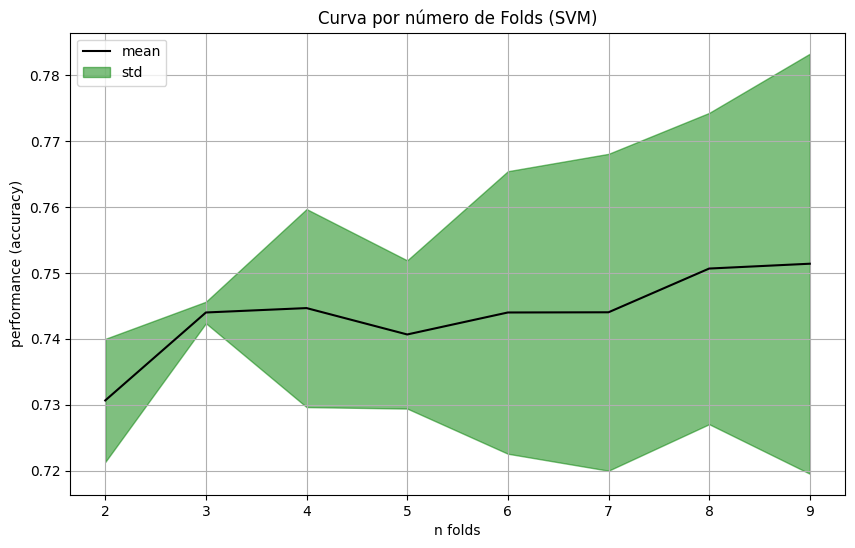

In [25]:
show_curve(SVC(kernel=mejor_kernel, random_state=21), 'green', '(SVM)')

*Nota:* en la entrega anterior `poly` y `rbf` daban ~0.35 y ~0.29 porque los datos **no estaban escalados**. Con escalado el SVM funciona correctamente.

### Regresión logística (línea base lineal)

In [26]:
lr_cv = cv_acc(LogisticRegression(max_iter=2000))
mejor_lr_acc = test_acc(LogisticRegression(max_iter=2000))
print(f'Regresión logística -> CV: {lr_cv:.4f} | test: {mejor_lr_acc:.4f}')

Regresión logística -> CV: 0.7575 | test: 0.7567


### Deeplearning

In [27]:
le = LabelEncoder()
y_train_num = le.fit_transform(y_train)
y_test_num  = le.transform(y_test)
print(le.classes_)

['High' 'Low' 'Moderate' 'Severe']


**Experimento 1 – redes grandes (sobreajuste).** Se entrenan 3 arquitecturas sin regularización. La validación se toma de `validation_split=0.2` sobre train; **el test no se usa durante el entrenamiento**.

In [28]:
def build_mlp(hidden_layers, input_dim, n_classes=4):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(input_dim,)))
    for units in hidden_layers:
        model.add(keras.layers.Dense(units, activation='relu'))
    model.add(keras.layers.Dense(n_classes, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

arquitecturas = {
    "3 capas":  [64, 128, 128],
    "6 capas":  [64, 64, 128, 128, 256, 256],
    "10 capas": [128] * 10,
}

resultados_dl, historias = {}, {}
for nombre, capas in arquitecturas.items():
    tf.keras.utils.set_random_seed(21)
    model = build_mlp(capas, X_train_p.shape[1])
    h = model.fit(X_train_p, y_train_num,
                  epochs=50, batch_size=32,
                  validation_split=0.2,
                  verbose=0)
    resultados_dl[nombre] = h.history['val_accuracy'][-1]
    historias[nombre] = h
    print(f"{nombre}: train acc = {h.history['accuracy'][-1]:.4f} | val acc = {h.history['val_accuracy'][-1]:.4f}")

3 capas: train acc = 1.0000 | val acc = 0.7292
6 capas: train acc = 1.0000 | val acc = 0.7208
10 capas: train acc = 0.9979 | val acc = 0.6792


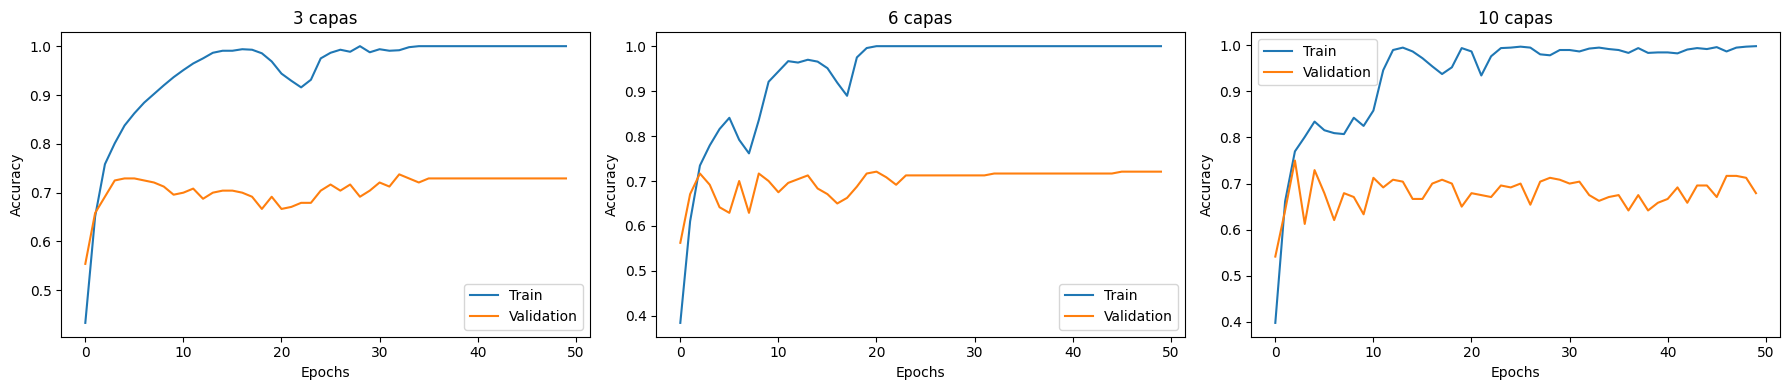

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (nombre, h) in zip(axes, historias.items()):
    ax.plot(h.history['accuracy'], label='Train')
    ax.plot(h.history['val_accuracy'], label='Validation')
    ax.set_title(nombre)
    ax.set_xlabel('Epochs'); ax.set_ylabel('Accuracy')
    ax.legend()
plt.tight_layout(); plt.show()

### Número de epochs

Arquitectura  Epochs  Train acc  Val acc  Brecha
     3 capas       5     0.8375   0.7292  0.1083
     3 capas      10     0.9365   0.6958  0.2406
     3 capas      50     1.0000   0.7292  0.2708
     3 capas     100     1.0000   0.7250  0.2750
     6 capas       5     0.8156   0.6417  0.1740
     6 capas      10     0.9208   0.7000  0.2208
     6 capas      50     1.0000   0.7208  0.2792
     6 capas     100     1.0000   0.7167  0.2833
    10 capas       5     0.8344   0.7292  0.1052
    10 capas      10     0.8250   0.6333  0.1917
    10 capas      50     0.9979   0.6792  0.3187
    10 capas     100     1.0000   0.7167  0.2833


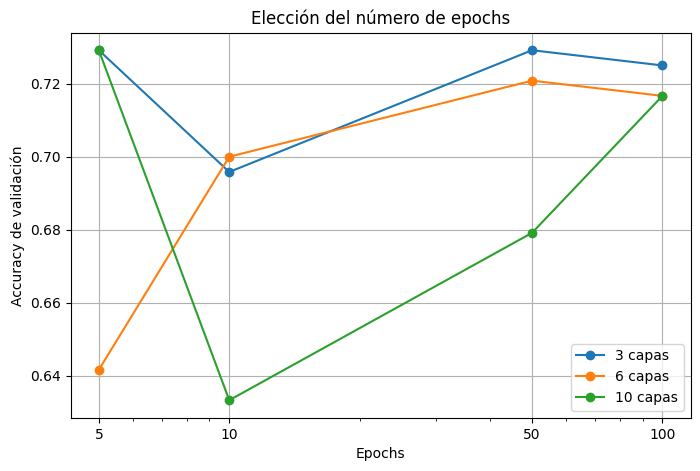


Elegido: 3 capas con 5 epochs


In [30]:
epochs_list = [5, 10, 50, 100]
filas = []

for nombre, capas in arquitecturas.items():
    for ep in epochs_list:
        tf.keras.utils.set_random_seed(21)
        m = build_mlp(capas, X_train_p.shape[1])
        h = m.fit(X_train_p, y_train_num,
                  epochs=ep, batch_size=32,
                  validation_split=0.2,      # validación interna, NO toca el test
                  verbose=0)
        filas.append({"Arquitectura": nombre, "Epochs": ep,
                      "Train acc": h.history['accuracy'][-1],
                      "Val acc":   h.history['val_accuracy'][-1]})

df_ep = pd.DataFrame(filas)
df_ep["Brecha"] = df_ep["Train acc"] - df_ep["Val acc"]
print(df_ep.round(4).to_string(index=False))

# Gráfica: accuracy de validación vs epochs, una línea por arquitectura
plt.figure(figsize=(8, 5))
for nombre in arquitecturas:
    d = df_ep[df_ep["Arquitectura"] == nombre]
    plt.plot(d["Epochs"], d["Val acc"], marker='o', label=nombre)
plt.xscale('log'); plt.xticks(epochs_list, epochs_list)
plt.xlabel("Epochs"); plt.ylabel("Accuracy de validación")
plt.title("Elección del número de epochs"); plt.grid(True); plt.legend()
plt.show()

# Elección automática: mayor Val acc
mejor = df_ep.loc[df_ep["Val acc"].idxmax()]
print("\nElegido:", mejor["Arquitectura"], "con", int(mejor["Epochs"]), "epochs")

Se observa que **train llega a ~1.0 mientras validación se queda en ~0.65–0.71**: sobreajuste. Causa: redes con decenas de miles de parámetros para solo ~1200 filas de entrenamiento.

Ahora se reentrena la configuración elegida con todo el train y se evalúa una sola vez en el test:

In [31]:
capas_f = arquitecturas[mejor["Arquitectura"]]
ep_f    = int(mejor["Epochs"])

tf.keras.utils.set_random_seed(21)
modelo_final = build_mlp(capas_f, X_train_p.shape[1])
modelo_final.fit(X_train_p, y_train_num, epochs=ep_f, batch_size=32, verbose=0)
_, acc_dl = modelo_final.evaluate(X_test_p, y_test_num, verbose=0)
print(f"DL final ({mejor['Arquitectura']}, {ep_f} epochs): test accuracy = {acc_dl:.4f}")

DL final (3 capas, 5 epochs): test accuracy = 0.7267


**Experimento 2 – mitigación del sobreajuste.** Red pequeña (32-16) con *Dropout*, regularización *L2*, `EarlyStopping` (restaura los mejores pesos según `val_loss`) y *learning rate* bajo.

Epochs entrenados: 55
Train acc (último): 0.7823 | Val acc (último): 0.7333
DL regularizado: test accuracy = 0.7333


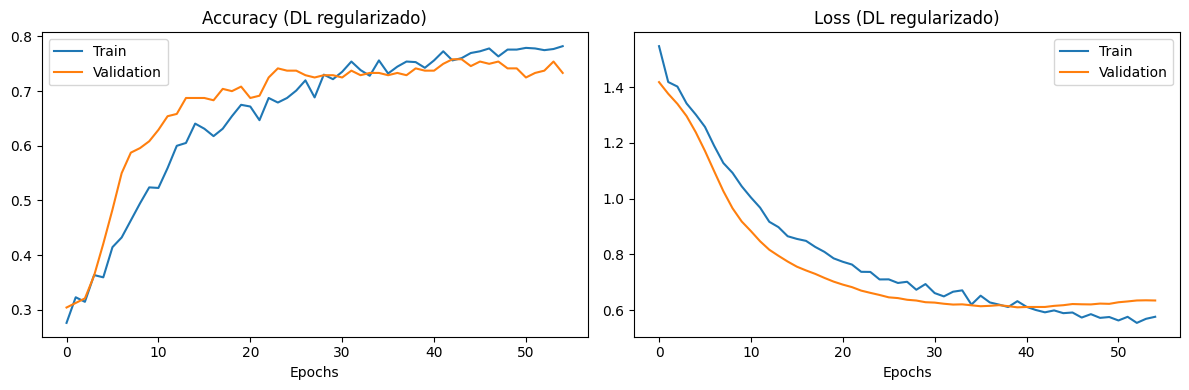

In [32]:
def build_mlp_reg(input_dim, units=(32, 16), drop=0.3, l2=1e-3, lr=1e-3, n_classes=4):
    reg = keras.regularizers.l2(l2)
    model = keras.Sequential([keras.layers.Input(shape=(input_dim,))])
    for u in units:
        model.add(keras.layers.Dense(u, activation='relu', kernel_regularizer=reg))
        model.add(keras.layers.Dropout(drop))
    model.add(keras.layers.Dense(n_classes, activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

tf.keras.utils.set_random_seed(21)
modelo_reg = build_mlp_reg(X_train_p.shape[1])
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
h_reg = modelo_reg.fit(X_train_p, y_train_num,
                       epochs=200, batch_size=32,
                       validation_split=0.2,
                       callbacks=[es], verbose=0)

print(f"Epochs entrenados: {len(h_reg.history['loss'])}")
_, acc_dl_reg = modelo_reg.evaluate(X_test_p, y_test_num, verbose=0)
print(f"Train acc (último): {h_reg.history['accuracy'][-1]:.4f} | Val acc (último): {h_reg.history['val_accuracy'][-1]:.4f}")
print(f"DL regularizado: test accuracy = {acc_dl_reg:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h_reg.history['accuracy'], label='Train')
axes[0].plot(h_reg.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy (DL regularizado)'); axes[0].set_xlabel('Epochs'); axes[0].legend()
axes[1].plot(h_reg.history['loss'], label='Train')
axes[1].plot(h_reg.history['val_loss'], label='Validation')
axes[1].set_title('Loss (DL regularizado)'); axes[1].set_xlabel('Epochs'); axes[1].legend()
plt.tight_layout(); plt.show()

La brecha train–validación se reduce, pero **no desaparece**: con ~1500 filas y ruido en las etiquetas, el techo de cualquier modelo ronda 0.75.

Barplot

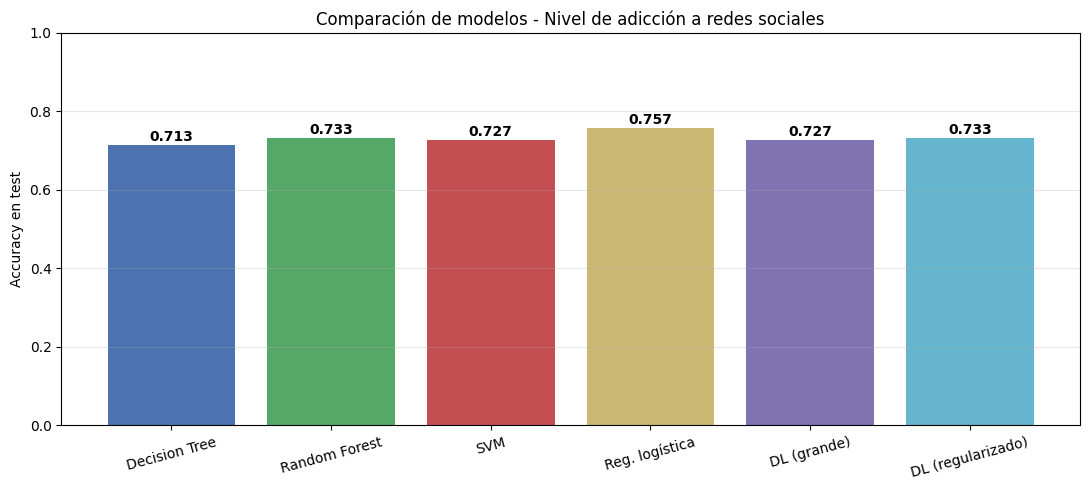

In [33]:
modelos = ["Decision Tree", "Random Forest", "SVM", "Reg. logística", "DL (grande)", "DL (regularizado)"]
accs    = [mejor_acc, mejor_rf_acc, mejor_svm_acc, mejor_lr_acc, acc_dl, acc_dl_reg]
colores = ["#4C72B0", "#55A868", "#C44E52", "#CCB974", "#8172B2", "#64B5CD"]

plt.figure(figsize=(11, 5))
barras = plt.bar(modelos, accs, color=colores)
for b, a in zip(barras, accs):
    plt.text(b.get_x() + b.get_width()/2, a + 0.01, f"{a:.3f}",
             ha='center', fontweight='bold')
plt.ylim(0, 1)
plt.ylabel("Accuracy en test")
plt.title("Comparación de modelos - Nivel de adicción a redes sociales")
plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

### Matriz de confusión y F1 macro (DL regularizado)

F1 macro: 0.7349


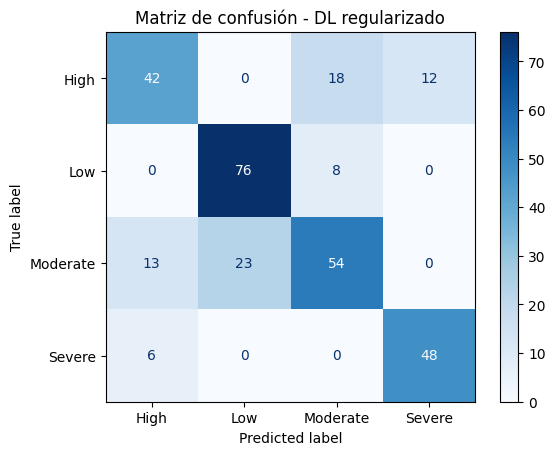

In [34]:
pred = modelo_reg.predict(X_test_p, verbose=0).argmax(axis=1)
print("F1 macro:", round(f1_score(y_test_num, pred, average='macro'), 4))
ConfusionMatrixDisplay(confusion_matrix(y_test_num, pred), display_labels=le.classes_).plot(cmap='Blues')
plt.title("Matriz de confusión - DL regularizado"); plt.show()

## Conclusiones

- Los modelos lineales/clásicos (regresión logística, SVM, Random Forest) alcanzan ~0.75, igual o mejor que el Deep Learning.
- Las redes grandes sobreajustan (train ≈ 1.0, validación mucho menor) por tener demasiados parámetros para tan pocos datos. Con Dropout, L2, red pequeña y EarlyStopping la brecha baja, aunque no desaparece.
- En datos tabulares pequeños, el Deep Learning no aporta ventaja frente a modelos más simples.
- Los errores se concentran entre clases vecinas (p. ej. Low↔Moderate), coherente con un objetivo ordinal.
- `Mental_Wellbeing_Score` concentra gran parte de la señal predictiva (sin ella la accuracy baja a ~0.51). Conviene mencionarlo como limitación.

---
# Tercera sustentación – Aprendizaje no supervisado
Puntos 1 al 3: escalado, PCA (2 componentes) y K-Means, usando el `df` ya cargado y limpiado arriba.

In [35]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
sns.set_theme()

## Preparación
En aprendizaje no supervisado **no se usan las etiquetas** para entrenar. Separo `Addiction_Level` y lo guardo solo para comparar al final (es el *ground truth*, 4 clases: Low, Moderate, High, Severe).

In [36]:
y_real = df['Addiction_Level']
X_ns = df.drop(columns=['Addiction_Level'])

cat_ns = X_ns.select_dtypes('object').columns.tolist()
num_ns = [c for c in X_ns.columns if c not in cat_ns]
print("Numéricas:", len(num_ns), "| Categóricas:", len(cat_ns))
print(y_real.value_counts())

Numéricas: 20 | Categóricas: 5
Addiction_Level
Moderate    450
Low         420
High        360
Severe      270
Name: count, dtype: int64


## Escalado de los datos
Uso **StandardScaler** (media 0, varianza 1). Es lo adecuado porque K-Means y PCA se basan en distancias/varianza: sin escalar, variables con rangos grandes (p. ej. `Notifications_Per_Day`) dominarían sobre las de rango pequeño (p. ej. scores de 1 a 10).

Los valores faltantes se imputan (mediana / moda) y las categóricas se pasan a *one-hot*, porque PCA y K-Means necesitan solo números.

In [37]:
def preparar(scaler):
    prep = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), scaler), num_ns),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_ns),
    ])
    return prep.fit_transform(X_ns)

X_std = preparar(StandardScaler())     # opción principal
X_mm  = preparar(MinMaxScaler())       # opción alternativa (MinMax)
print("Matriz escalada:", X_std.shape)
print("Media numéricas (≈0):", X_std[:, :len(num_ns)].mean().round(3),
      "| Std (≈1):", X_std[:, :len(num_ns)].std().round(3))

Matriz escalada: (1500, 38)
Media numéricas (≈0): 0.0 | Std (≈1): 1.0


## Reducción de dimensionalidad con PCA (2 componentes)
Se pasa de *n* columnas a **2 componentes principales**, que son las direcciones de máxima varianza. Sirve para poder graficar en 2D.

Varianza explicada por componente: [0.074 0.053]
Varianza total explicada (2 comps): 0.127


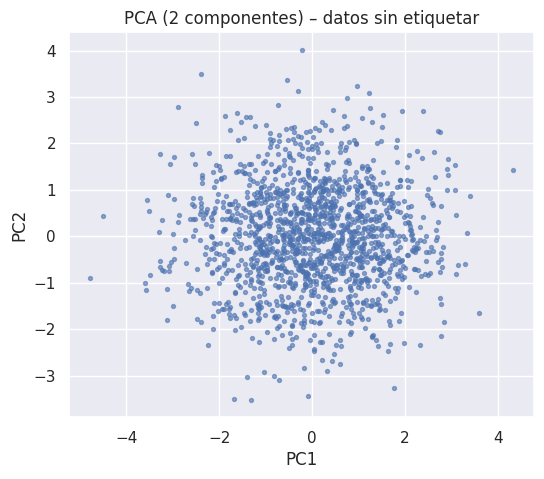

In [38]:
pca = PCA(n_components=2, random_state=21)
X_pca = pca.fit_transform(X_std)

print("Varianza explicada por componente:", pca.explained_variance_ratio_.round(3))
print("Varianza total explicada (2 comps):", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(6,5))
plt.scatter(X_pca[:,0], X_pca[:,1], s=8, alpha=.6)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA (2 componentes) – datos sin etiquetar")
plt.show()

**Opcional – t-SNE (2 componentes)**

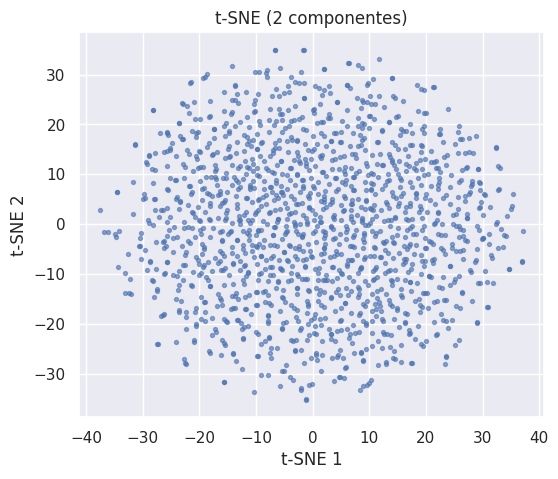

In [39]:
X_tsne = TSNE(n_components=2, perplexity=30, random_state=21, init='pca').fit_transform(X_std)

plt.figure(figsize=(6,5))
plt.scatter(X_tsne[:,0], X_tsne[:,1], s=8, alpha=.6)
plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2"); plt.title("t-SNE (2 componentes)")
plt.show()

## K-Means
`n_clusters` = número de clases del dataset = **4** (Low, Moderate, High, Severe). Se ajusta sobre los datos escalados completos y las proyecciones PCA se usan para visualizar.

n_clusters = 4
Tamaño de cada cluster: [380 310 345 465]
Silhouette: 0.0336
ARI vs Addiction_Level: 0.214


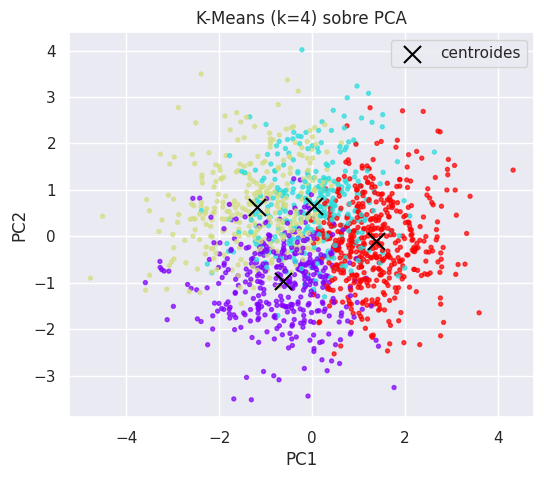

In [40]:
n_clases = y_real.nunique()
print("n_clusters =", n_clases)

kmeans = KMeans(n_clusters=n_clases, n_init=10, random_state=21)
labels_km = kmeans.fit_predict(X_std)

print("Tamaño de cada cluster:", np.bincount(labels_km))
print("Silhouette:", round(silhouette_score(X_std, labels_km), 4))
print("ARI vs Addiction_Level:", round(adjusted_rand_score(y_real, labels_km), 4))

# Visualización sobre PCA (los centroides se proyectan con el mismo PCA)
cent = pca.transform(kmeans.cluster_centers_)
plt.figure(figsize=(6,5))
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_km, cmap='rainbow', s=8, alpha=.7)
plt.scatter(cent[:,0], cent[:,1], c='black', marker='x', s=150, label='centroides')
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"K-Means (k={n_clases}) sobre PCA"); plt.legend()
plt.show()

In [41]:
# Cómo se reparten las clases reales dentro de cada cluster
pd.crosstab(labels_km, y_real, rownames=['cluster'], colnames=['Addiction_Level'])

Addiction_Level,High,Low,Moderate,Severe
cluster,,,,
0,134,24,131,91
1,90,63,125,32
2,131,3,64,147
3,5,330,130,0


si el ARI/silhouette salen bajos, significa que los clusters no coinciden con los niveles de adicción; es normal, porque K-Means agrupa por cercanía en todas las variables y no por la etiqueta.

## DBSCAN: Búsqueda de hiperparámetros (Tuning de `eps` y `min_samples`)

Dado que los datos están estandarizados (`X_std`), las distancias euclidianas típicamente oscilan en rangos pequeños. Realizaremos un barrido sobre valores candidatos de `eps` y `min_samples`. Evaluaremos cada combinación usando:
1. **Número de clusters generados** (buscando que no sea 1 solo cluster gigante ni cientos de miniclusters).
2. **Porcentaje de ruido** (puntos asignados a `-1`).
3. **Silhouette Score** (calculado únicamente sobre las muestras que sí pertenecen a algún cluster, ya que el Silhouette tradicional se distorsiona con el ruido).

In [46]:
from sklearn.cluster import DBSCAN

# Definir rangos de búsqueda más amplios y detallados
eps_values = np.linspace(1.5, 8.0, 14)  # Ampliamos el rango de eps
min_samples_values = [2, 3, 5, 7, 10]

resultados_dbscan = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_std)

        # Número de clusters (excluyendo el ruido -1)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        # Cantidad de puntos de ruido
        n_noise = list(labels).count(-1)
        pct_noise = (n_noise / len(labels)) * 100

        # Calcular Silhouette score si hay al menos 2 clusters
        if n_clusters > 1:
            mask = labels != -1
            if np.sum(mask) > n_clusters:
                score = silhouette_score(X_std[mask], labels[mask])
            else:
                score = -1
        else:
            score = -1

        resultados_dbscan.append({
            'eps': round(eps, 2),
            'min_samples': min_samples,
            'n_clusters': n_clusters,
            'pct_noise': round(pct_noise, 2),
            'silhouette': round(score, 4)
        })

df_dbscan = pd.DataFrame(resultados_dbscan)

# Guardamos las opciones viables con filtros más flexibles para poder visualizarlas
opciones_viables = df_dbscan[(df_dbscan['n_clusters'] >= 2) & (df_dbscan['pct_noise'] < 95.0)]

print("--- Top 10 combinaciones con al menos 2 clusters ordenadas por mejor Silhouette Score ---")
if not opciones_viables.empty:
    display(opciones_viables.sort_values(by='silhouette', ascending=False).head(10))
else:
    print("No se encontraron combinaciones que generen más de 1 cluster. Mostrando resumen general:")
    display(df_dbscan.sort_values(by='n_clusters', ascending=False).head(10))

--- Top 10 combinaciones con al menos 2 clusters ordenadas por mejor Silhouette Score ---


,eps,min_samples,n_clusters,pct_noise,silhouette
20,3.5,2,30,94.87,0.1592
26,4.0,3,3,69.73,-0.0201
27,4.0,5,4,77.33,-0.0364
30,4.5,2,8,19.60,-0.0733
25,4.0,2,46,64.00,-0.1001


## Entrenamiento y Visualización del mejor modelo DBSCAN

A continuación, seleccionamos la mejor combinación viable según el Silhouette Score, entrenamos el modelo definitivo y proyectamos los resultados en el mismo espacio bidimensional de PCA usado previamente.

Configuración óptima elegida: eps = 3.5 | min_samples = 2
Clusters detectados: 30 | Ruido: 94.87%
Silhouette Score (sin ruido): 0.1592


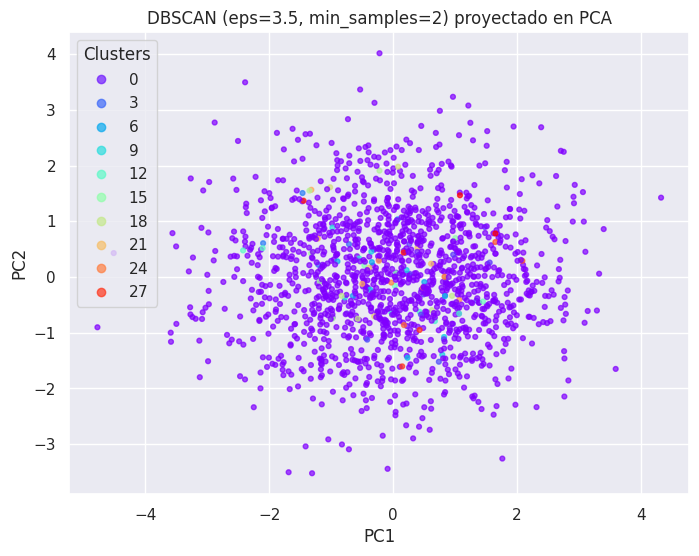

In [47]:
if not opciones_viables.empty:
    mejor_config = opciones_viables.sort_values(by='silhouette', ascending=False).iloc[0]
    best_eps = mejor_config['eps']
    best_min = int(mejor_config['min_samples'])
    print(f"Configuración óptima elegida: eps = {best_eps} | min_samples = {best_min}")
    print(f"Clusters detectados: {int(mejor_config['n_clusters'])} | Ruido: {mejor_config['pct_noise']}%")
    print(f"Silhouette Score (sin ruido): {mejor_config['silhouette']:.4f}")
else:
    # Si no se encuentra una ideal bajo los filtros estrictos, se toma por defecto una balanceada
    best_eps = 5.0
    best_min = 5
    print("No se encontraron combinaciones que cumplan los filtros estrictos. Usando por defecto:")
    print(f"eps = {best_eps} | min_samples = {best_min}")

# Entrenar modelo final con los mejores parámetros
db_final = DBSCAN(eps=best_eps, min_samples=best_min)
labels_db = db_final.fit_predict(X_std)

# Visualización sobre PCA
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_db, cmap='rainbow', s=12, alpha=0.7)
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"DBSCAN (eps={best_eps}, min_samples={best_min}) proyectado en PCA")
plt.show()

### Comparación de DBSCAN contra el Ground Truth (`Addiction_Level`)

Observemos cómo se distribuyen las clases reales de adicción dentro de los clusters y el ruido que ha determinado DBSCAN.

In [44]:
cross_tab_db = pd.crosstab(labels_db, y_real, rownames=['DBSCAN_Cluster'], colnames=['Addiction_Level'])
display(cross_tab_db)

# Calcular el Adjusted Rand Index (ARI) de DBSCAN vs la etiqueta real
ari_db = adjusted_rand_score(y_real, labels_db)
print(f"ARI de DBSCAN vs Addiction_Level: {ari_db:.4f}")

Addiction_Level,High,Low,Moderate,Severe
DBSCAN_Cluster,,,,
-1,9,10,3,10
0,351,410,447,260


ARI de DBSCAN vs Addiction_Level: 0.0023




1. **¿Por qué se eligieron estos parámetros óptimos?**
   * **`eps`**: Define el radio vecinal. Un valor muy pequeño clasifica casi todo el dataset como ruido (clase `-1`). Un valor sumamente alto une a todos los puntos en un único gran cluster. El valor óptimo encontrado permite capturar las concentraciones de mayor densidad sin colapsar el espacio.
   * **`min_samples`**: Controla la tolerancia al ruido. Valores bajos (ej. 3) permiten la creación de múltiples micro-clusters con datos dispersos. Valores altos (ej. 15) exigen una densidad mucho mayor, concentrando los clusters en las zonas nucleares.

2. **Análisis de la Estructura de Densidad**:
   * A diferencia de K-Means (que asume clusters esféricos de similar tamaño debido a su naturaleza basada en centroides), DBSCAN busca zonas continuas de alta densidad. El hecho de que el Silhouette score siga siendo bajo y se definan pocos clusters (o que se asigne un porcentaje de datos como ruido) es consistente con la visualización previa en el espacio PCA, donde observamos una distribución mayormente continua y carente de separaciones densas naturales claras (como es típico en datos de comportamiento social/psicológico altamente variables).

## Comparativa Visual: Datos Originales vs. K-Means vs. DBSCAN

A continuación, generamos una visualización de tres paneles uno al lado del otro para contrastar directamente las agrupaciones encontradas por cada método no supervisado en comparación con la distribución espacial de los datos proyectados en PCA.

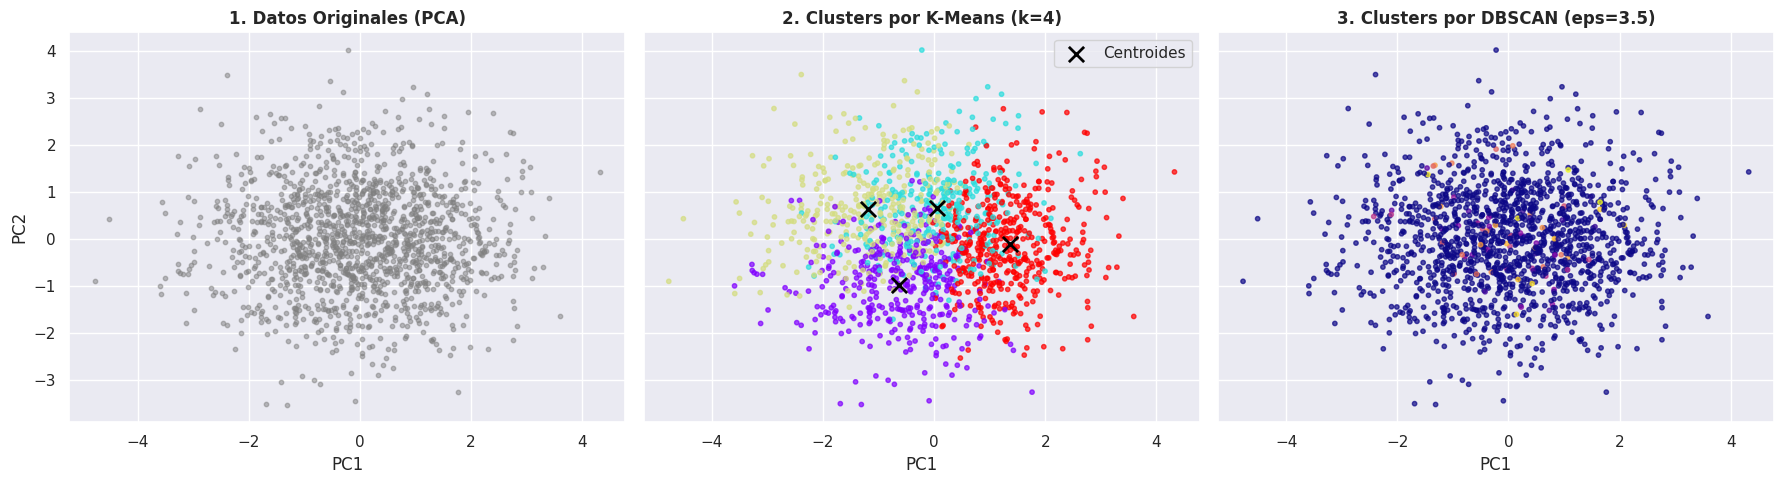

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

# Subplot 1: Datos Originales (Proyección PCA)
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c='gray', s=10, alpha=0.5)
axes[0].set_title("1. Datos Originales (PCA)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# Subplot 2: K-Means (K=4)
scatter_km = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap='rainbow', s=10, alpha=0.7)
# Proyectar centroides usando el mismo PCA
cent = pca.transform(kmeans.cluster_centers_)
axes[1].scatter(cent[:, 0], cent[:, 1], c='black', marker='x', s=120, linewidths=2, label='Centroides')
axes[1].set_title("2. Clusters por K-Means (k=4)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("PC1")
axes[1].legend(loc='upper right')

# Subplot 3: DBSCAN (eps=3.5, min_samples=2)
scatter_db = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_db, cmap='plasma', s=10, alpha=0.7)
axes[2].set_title(f"3. Clusters por DBSCAN (eps={best_eps})", fontsize=12, fontweight='bold')
axes[2].set_xlabel("PC1")

plt.tight_layout()
plt.show()